Episode  500 | steps =  10 | total reward =   91.0 | epsilon = 0.082
Episode 1000 | steps =  10 | total reward =   91.0 | epsilon = 0.050
Episode 1500 | steps =  10 | total reward =   91.0 | epsilon = 0.050
Episode 2000 | steps =  11 | total reward =   86.0 | epsilon = 0.050
Episode 2500 | steps =  10 | total reward =   91.0 | epsilon = 0.050
Episode 3000 | steps =  10 | total reward =   91.0 | epsilon = 0.050

Learned path:
[(0, 0), (0, 1), (0, 2), (1, 2), (2, 2), (2, 3), (2, 4), (2, 5), (3, 5), (4, 5), (5, 5)]

Number of steps: 10
Goal reached successfully!


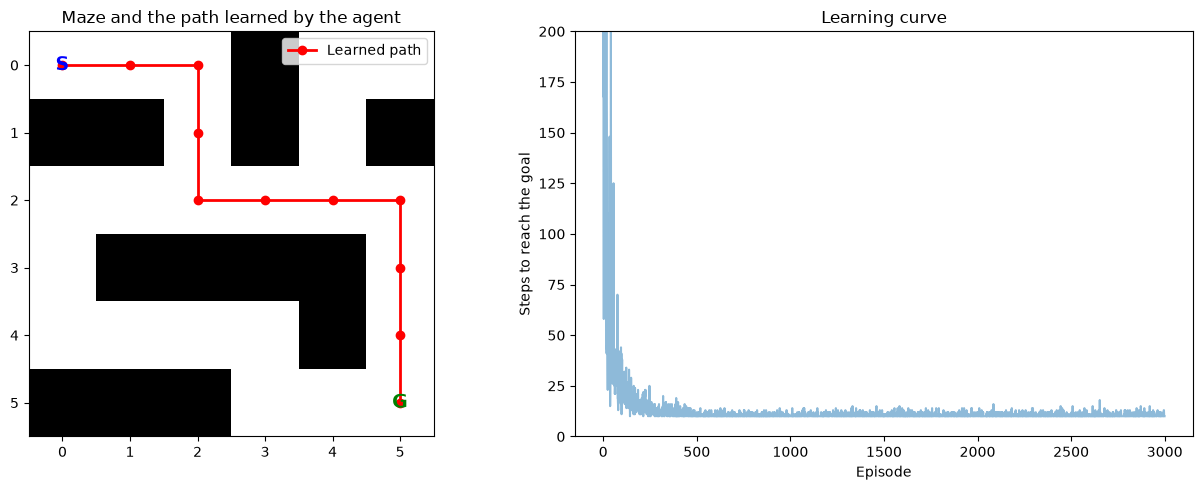

In [2]:
# ============================================================
# Practical: Q-Learning for Maze Navigation
# ============================================================

# Step 1: Import libraries
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap


# Step 2: Create the maze
# 0 = Free cell
# 1 = Wall

maze = np.array([
    [0, 0, 0, 1, 0, 0],
    [1, 1, 0, 1, 0, 1],
    [0, 0, 0, 0, 0, 0],
    [0, 1, 1, 1, 1, 0],
    [0, 0, 0, 0, 1, 0],
    [1, 1, 1, 0, 0, 0]
])

rows, cols = maze.shape

# Starting and goal positions
start = (0, 0)
goal = (5, 5)


# Step 3: Define actions
# 0 = Up, 1 = Down, 2 = Left, 3 = Right

actions = [
    (-1, 0),
    (1, 0),
    (0, -1),
    (0, 1)
]

action_names = ["Up", "Down", "Left", "Right"]


# Step 4: Define rewards

GOAL_REWARD = 100
STEP_REWARD = -1
WALL_REWARD = -5


# Step 5: Create the environment function

def step(state, action):

    r, c = state

    dr, dc = actions[action]

    nr = r + dr
    nc = c + dc

    # Check whether the move is outside the maze
    if nr < 0 or nr >= rows or nc < 0 or nc >= cols:
        return state, WALL_REWARD, False

    # Check whether the next cell is a wall
    if maze[nr, nc] == 1:
        return state, WALL_REWARD, False

    next_state = (nr, nc)

    # Check whether the agent reached the goal
    if next_state == goal:
        return next_state, GOAL_REWARD, True

    # Normal movement
    return next_state, STEP_REWARD, False


# Step 6: Initialize Q-learning parameters

alpha = 0.1
gamma = 0.9

epsilon = 1.0
eps_min = 0.05
eps_decay = 0.995

episodes = 3000
max_steps = 200

# Q-table: rows x columns x number of actions
Q = np.zeros((rows, cols, len(actions)))

# Store training results
steps_per_episode = []
reward_per_episode = []


# Step 7: Train the agent using Q-learning

for ep in range(episodes):

    state = start
    total_reward = 0

    for t in range(max_steps):

        # Epsilon-greedy action selection

        if np.random.rand() < epsilon:

            # Explore: choose a random action
            a = np.random.randint(len(actions))

        else:

            # Exploit: choose the best action
            q_values = Q[state[0], state[1]]

            # Random tie-breaking between equally good actions
            best_actions = np.flatnonzero(
                q_values == np.max(q_values)
            )

            a = np.random.choice(best_actions)

        # Execute the action
        next_state, reward, done = step(state, a)

        # Calculate the best future Q-value
        best_next = np.max(
            Q[next_state[0], next_state[1]]
        )

        # Q-learning update rule
        if done:

            target = reward

        else:

            target = reward + gamma * best_next

        Q[state[0], state[1], a] += alpha * (
            target - Q[state[0], state[1], a]
        )

        # Move to the next state
        state = next_state

        # Accumulate reward
        total_reward += reward

        # Stop if the goal is reached
        if done:
            break

    # Reduce exploration after each episode
    epsilon = max(eps_min, epsilon * eps_decay)

    # Store training results
    steps_per_episode.append(t + 1)
    reward_per_episode.append(total_reward)

    # Display progress every 500 episodes
    if (ep + 1) % 500 == 0:

        print(
            f"Episode {ep + 1:4d} | "
            f"steps = {t + 1:3d} | "
            f"total reward = {total_reward:6.1f} | "
            f"epsilon = {epsilon:.3f}"
        )


# Step 8: Extract the learned path

state = start
path = [start]

# Avoid revisiting cells during path extraction
visited = {start}

while state != goal and len(path) < rows * cols:

    q_values = Q[state[0], state[1]]

    # Sort actions from highest Q-value to lowest
    action_order = np.argsort(q_values)[::-1]

    moved = False

    # Try the actions in Q-value order
    for a in action_order:

        next_state, reward, done = step(state, a)

        # Select a valid move that does not revisit a cell
        if next_state != state and next_state not in visited:

            state = next_state
            path.append(state)
            visited.add(state)

            moved = True
            break

    # Stop if no suitable action is available
    if not moved:
        print("The learned policy got stuck.")
        break


# Step 9: Display the learned path

print("\nLearned path:")
print(path)

print("\nNumber of steps:", len(path) - 1)

if state == goal:
    print("Goal reached successfully!")
else:
    print("Goal was not reached by the learned policy.")




# Step 11: Plot the maze and learning curve

fig, ax = plt.subplots(1, 2, figsize=(13, 5))


# Plot 1: Maze and learned path

ax[0].imshow(
    maze,
    cmap=ListedColormap(["white", "black"])
)

# Separate row and column coordinates
ys, xs = zip(*path)

# Plot the learned path
ax[0].plot(
    xs,
    ys,
    "r-o",
    linewidth=2,
    label="Learned path"
)

# Mark the starting position
ax[0].text(
    start[1],
    start[0],
    "S",
    color="blue",
    ha="center",
    va="center",
    fontsize=14,
    fontweight="bold"
)

# Mark the goal position
ax[0].text(
    goal[1],
    goal[0],
    "G",
    color="green",
    ha="center",
    va="center",
    fontsize=14,
    fontweight="bold"
)

ax[0].set_title("Maze and the path learned by the agent")
ax[0].legend(loc="upper right")

ax[0].set_xticks(range(cols))
ax[0].set_yticks(range(rows))


# Plot 2: Learning curve

ax[1].plot(
    steps_per_episode,
    alpha=0.5
)

ax[1].set_xlabel("Episode")
ax[1].set_ylabel("Steps to reach the goal")

ax[1].set_title("Learning curve")

ax[1].set_ylim(0, max_steps)


# Display both plots
plt.tight_layout()
plt.show()